## 1.2 Koneksi ke Database Neo4j

Pada tahap ini, dilakukan koneksi antara Python dan database Neo4j menggunakan Neo4j Python Driver. Selanjutnya, dibuat contoh graf pertemanan dengan node `Person` dan relationship `KNOWS` untuk memahami cara membuat node, menghubungkan node, dan mengambil data dari Neo4j.

In [ ]:

from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "....")

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")
finally:
    driver.close()

Koneksi ke Neo4j berhasil!


C:\Users\MSI-PC\AppData\Local\Temp\ipykernel_12472\1253015816.py:9: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


### Membuat Graf Pertemanan

Pada bagian ini, dibuat node untuk Arthur, Guinevere, Lancelot, dan Merlin. Arthur dihubungkan dengan ketiga nama lainnya menggunakan relationship `KNOWS`. Setelah itu, dilakukan query untuk menampilkan nama teman Arthur dari database Neo4j.

In [ ]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )


def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend_name
            """,
            name=name
        )

        for record in result:
            print(record["friend_name"])


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Teman Arthur:")
    print_friends(driver, "Arthur")


Teman Arthur:
Guinevere
Lancelot
Merlin


Berdasarkan hasil eksekusi, koneksi Python dengan Neo4j berhasil dilakukan. Graf pertemanan juga berhasil dibuat, ditunjukkan dengan munculnya nama Guinevere, Lancelot, dan Merlin sebagai teman Arthur. Hasil menunjukkan data dapat disimpan dan diambil kembali menggunakan query Cypher melalui Python.

### Pertanyaan Pendahuluan (*Checkpoint*)

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan adalah `neo4j`.

**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance!**

Database lain dapat diakses dengan menentukan nama database pada `driver.session(database="nama_database")`. Untuk melihat daftar database yang tersedia, dapat digunakan query Cypher `SHOW DATABASES`.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf yang dibuat merupakan graf berarah (*directed graph*), karena relationship `KNOWS` memiliki arah dari Arthur menuju Guinevere, Lancelot, dan Merlin.

## 1.3 Proses Impor Data RetailRocket ke Database Neo4j

Pada tahap ini, dataset RetailRocket diperiksa terlebih dahulu, kemudian diimpor ke Neo4j. Data pengunjung dan produk disimpan sebagai node `Visitor` dan `Item`, sedangkan aktivitas pengunjung disimpan sebagai relationship sesuai jenis interaksinya.

### 2. Membaca dan Memeriksa Dataset

Dataset `events.csv` diperiksa untuk mengetahui ukuran data, nama kolom, jenis interaksi, nilai kosong, dan rentang timestamp. Hasil pemeriksaan ini digunakan untuk memahami data sebelum diimpor ke Neo4j.

In [6]:
import pandas as pd
from pathlib import Path
from neo4j import GraphDatabase
from tqdm.notebook import tqdm


In [7]:
# Lokasi dataset
csv_path = Path("data/events.csv")

# Membaca dataset
df = pd.read_csv(csv_path)

# Melihat ukuran dan isi dataset
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [8]:
# Melihat jumlah setiap jenis interaksi
print("Jumlah setiap jenis interaksi:")
print(df["event"].value_counts())

# Memeriksa data transactionid yang kosong
print("\nJumlah transactionid kosong:")
print(df["transactionid"].isna().sum())

# Memeriksa rentang waktu dataset
print("\nRentang timestamp:")
print("Minimum:", df["timestamp"].min())
print("Maksimum:", df["timestamp"].max())

Jumlah setiap jenis interaksi:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Jumlah transactionid kosong:
2733644

Rentang timestamp:
Minimum: 1430622004384
Maksimum: 1442545187788


**Hasil pemeriksaan**

Dataset terdiri dari 2.756.101 baris dan 5 kolom. Jenis interaksi yang paling banyak adalah `view` sebanyak 2.664.312, diikuti `addtocart` sebanyak 69.332 dan `transaction` sebanyak 22.457. Sebanyak 2.733.644 nilai `transactionid` kosong, karena kolom tersebut umumnya terisi pada interaksi transaksi. Data memiliki timestamp dari 1430622004384 hingga 1442545187788.

In [9]:
import neo4j

print("Versi Neo4j Driver:", neo4j.__version__)

Versi Neo4j Driver: 4.2.1


### 3. Membuat Koneksi dan Fungsi Impor

Pada tahap ini, dibuat koneksi ke Neo4j dan dua fungsi untuk membantu proses impor. Fungsi `create_constraints()` menjaga agar ID Visitor dan Item tetap unik, sedangkan `import_batch()` mengubah setiap baris data menjadi node dan relationship sesuai jenis interaksinya.

In [ ]:
# Konfigurasi koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "....."

# Fungsi untuk membuat constraint
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemId IS UNIQUE
    """)

# Fungsi untuk mengimpor satu batch
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

### 4. Impor Data Secara Batch

Dataset diimpor secara bertahap dengan ukuran 10.000 baris per batch. Cara ini digunakan agar proses impor lebih terkelola karena ukuran dataset cukup besar. Setelah seluruh batch diproses, data siap diverifikasi di Neo4j.

In [11]:
# Lokasi dataset
csv_file_path = Path("data/events.csv")

# Ukuran setiap batch
batch_size = 10000

# Periksa keberadaan file
if not csv_file_path.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {csv_file_path}")

# Membaca jumlah baris data
total_rows = sum(1 for _ in open(csv_file_path, encoding="utf-8")) - 1
total_chunks = (total_rows + batch_size - 1) // batch_size

print("Jumlah baris data:", total_rows)
print("Jumlah batch:", total_chunks)

# Proses impor
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:
        # Membuat constraint
        create_constraints(session)

        print("\nMemulai proses impor data...")

        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        for chunk in tqdm(chunks, total=total_chunks, desc="Impor batch"):
            # Menangani transactionid yang kosong
            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            records = chunk.to_dict(orient="records")

            # Driver Neo4j 4.2.1 menggunakan write_transaction
            session.write_transaction(import_batch, records)

print("\nProses impor selesai!")

Jumlah baris data: 2756101
Jumlah batch: 276


C:\Users\MSI-PC\AppData\Local\Temp\ipykernel_12472\3352732438.py:20: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()



Memulai proses impor data...


Impor batch:   0%|          | 0/276 [00:00<?, ?it/s]


Proses impor selesai!


### 5. Verifikasi Hasil Impor

Verifikasi dilakukan dengan menghitung jumlah node `Visitor`, node `Item`, dan setiap jenis relationship di Neo4j. Hasilnya digunakan untuk memastikan bahwa data telah masuk ke database.

In [12]:
from neo4j import GraphDatabase

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:

        # Menghitung jumlah Visitor
        result = session.run(
            "MATCH (v:Visitor) RETURN count(v) AS jumlah"
        )
        print("Jumlah Visitor:", result.single()["jumlah"])

        # Menghitung jumlah Item
        result = session.run(
            "MATCH (i:Item) RETURN count(i) AS jumlah"
        )
        print("Jumlah Item:", result.single()["jumlah"])

        # Menghitung jumlah relasi berdasarkan jenisnya
        result = session.run("""
            MATCH ()-[r]->()
            RETURN type(r) AS jenis_relasi, count(r) AS jumlah
            ORDER BY jumlah DESC
        """)

        print("\nJumlah relasi:")
        for record in result:
            print(f"{record['jenis_relasi']}: {record['jumlah']}")

Jumlah Visitor: 1407580
Jumlah Item: 235061

Jumlah relasi:
VIEWED: 2664312
ADDED_TO_CART: 69332
BOUGHT: 22457
KNOWS: 3


Berdasarkan hasil verifikasi, data RetailRocket berhasil diimpor ke Neo4j. Terdapat 1.407.580 node `Visitor` dan 235.061 node `Item`. Ketiga relationship dari dataset juga berhasil terbentuk sesuai jumlah interaksinya. Relationship `KNOWS` sebanyak 3 berasal dari contoh graf pertemanan pada bagian 1.2, sehingga tidak termasuk interaksi RetailRocket.

## 2.1 Wrangling dan Exploratory Data Analysis (EDA)

#### 1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas.Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

Data dibagi menjadi dua periode, yaitu P1 sebagai data training dan P2 sebagai data testing. P1 digunakan untuk membangun model, sedangkan P2 digunakan untuk mengevaluasi hasil rekomendasi pada periode berikutnya.

- **P1 (Training):** 3 Mei–14 Juli 2015.
- **P2 (Testing):** 15 Juli–18 September 2015.

#### 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

Kolom `timestamp` dikonversi dari Unix epoch dalam milidetik menjadi format datetime. Data kemudian dipisahkan berdasarkan periode P1 dan P2, lalu disimpan ke file CSV agar dapat digunakan pada analisis berikutnya.

In [ ]:
# Membaca dataset RetailRocket
csv_path = Path("data/events.csv")
df = pd.read_csv(csv_path)

# Mengubah timestamp Unix epoch milidetik menjadi datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# Menentukan periode training (P1) dan testing (P2)
p1_start = "2015-05-03"
p1_end   = "2015-07-14"

p2_start = "2015-07-15"
p2_end   = "2015-09-18"

# Filter data berdasarkan periode
p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < "2015-07-15")
].copy()

p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < "2015-09-19")
].copy()

# Simpan hasil filter ke CSV
Path("data").mkdir(exist_ok=True)

p1.drop(columns=["datetime"]).to_csv(
    "data/events_P1.csv", index=False
)

p2.drop(columns=["datetime"]).to_csv(
    "data/events_P2.csv", index=False
)

# Tampilkan ringkasan hasil
print("Jumlah data P1 (training):", len(p1))
print("Jumlah data P2 (testing):", len(p2))

print("\nRentang tanggal P1:")
print(p1["datetime"].min(), "sampai", p1["datetime"].max())

print("\nRentang tanggal P2:")
print(p2["datetime"].min(), "sampai", p2["datetime"].max())

print("\nTotal data hasil filter:", len(p1) + len(p2))

Jumlah data P1 (training): 1510682
Jumlah data P2 (testing): 1245419

Rentang tanggal P1:
2015-05-03 03:00:04.384000 sampai 2015-07-14 23:59:56.104000

Rentang tanggal P2:
2015-07-15 00:00:00.336000 sampai 2015-09-18 02:59:47.788000

Total data hasil filter: 2756101


Hasil filter menghasilkan 1.510.682 baris pada P1 dan 1.245.419 baris pada P2. Jumlah keduanya sama dengan jumlah data awal, sehingga seluruh data telah terbagi ke dalam kedua periode tersebut. File `events_P1.csv` dan `events_P2.csv` selanjutnya digunakan pada tahap VSM dan evaluasi rekomendasi.

#### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

Pada tahap ini, dilakukan query ke Neo4j untuk menghitung jumlah Visitor, Item, dan relationship pada periode P1. Query dijalankan menggunakan Python API Neo4j, kemudian hasilnya ditampilkan dalam bentuk tabel.

In [ ]:
# Batas periode P1 (training): 3 Mei - 14 Juli 2015
start_ts = 1430622000000
end_ts = 1436918400000

# Query Cypher untuk mendapatkan komposisi subgraph P1
query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ts
  AND r.timestamp < $end_ts
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS jumlah_interaksi,
    sum(CASE WHEN type(r) = 'VIEWED' THEN 1 ELSE 0 END) AS viewed,
    sum(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 ELSE 0 END) AS added_to_cart,
    sum(CASE WHEN type(r) = 'BOUGHT' THEN 1 ELSE 0 END) AS bought
"""

# Menjalankan query melalui Python API Neo4j
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(
            query,
            start_ts=start_ts,
            end_ts=end_ts
        )
        record = result.single()

# Menampilkan hasil dalam tabel
komposisi = pd.DataFrame({
    "Komponen": [
        "Visitor",
        "Item",
        "VIEWED",
        "ADDED_TO_CART",
        "BOUGHT",
        "Total Interaksi"
    ],
    "Jumlah": [
        record["jumlah_visitor"],
        record["jumlah_item"],
        record["viewed"],
        record["added_to_cart"],
        record["bought"],
        record["jumlah_interaksi"]
    ]
})

print("Komposisi Subgraph P1 (Training)")
display(komposisi)

Komposisi Subgraph P1 (Training)


,Komponen,Jumlah
0,Visitor,765439
1,Item,181334
2,VIEWED,1461556
3,ADDED_TO_CART,36999
4,BOUGHT,12127
5,Total Interaksi,1510682


**Penjelasan query Cypher**

- `MATCH` mengambil hubungan antara Visitor dan Item.
- `WHERE` membatasi interaksi pada periode P1 dan memilih tiga jenis relationship yang digunakan.
- `count(DISTINCT v)` dan `count(DISTINCT i)` menghitung jumlah Visitor dan Item yang unik.
- `count(r)` menghitung total interaksi, sedangkan `sum(CASE WHEN ...)` menghitung setiap jenis relationship.

Berdasarkan hasil query, subgraph P1 memiliki 765.439 Visitor dan 181.334 Item. Relationship yang paling banyak adalah `VIEWED` sebanyak 1.461.556, sedangkan yang paling sedikit adalah `BOUGHT` sebanyak 12.127.

#### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimanakarakteristiknya (dimensi, shape, plot networkx, dst.)!

VSM dilakukan dengan membentuk matriks User–Item dari data P1. Baris matriks mewakili Visitor dan kolom mewakili Item. Selanjutnya, cosine similarity digunakan untuk melihat kemiripan pola interaksi antar-User.

In [18]:
# Membuat matriks User–Item

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt

# Membaca data P1
p1 = pd.read_csv("data/events_P1.csv")

# Membuat indeks untuk setiap Visitor dan Item
user_ids = p1["visitorid"].unique()
item_ids = p1["itemid"].unique()

user_index = {user: idx for idx, user in enumerate(user_ids)}
item_index = {item: idx for idx, item in enumerate(item_ids)}

# Mengubah interaksi menjadi matriks sparse User-Item
rows = p1["visitorid"].map(user_index).to_numpy()
cols = p1["itemid"].map(item_index).to_numpy()
values = np.ones(len(p1), dtype=np.int32)

user_item_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

print("Dimensi matriks User-Item:", user_item_matrix.ndim)
print("Shape matriks:", user_item_matrix.shape)
print("Jumlah nilai nonzero:", user_item_matrix.nnz)

density = (
    user_item_matrix.nnz /
    (user_item_matrix.shape[0] * user_item_matrix.shape[1])
) * 100

print(f"Kepadatan matriks: {density:.6f}%")

Dimensi matriks User-Item: 2
Shape matriks: (765439, 181334)
Jumlah nilai nonzero: 1168246
Kepadatan matriks: 0.000842%


Matriks User–Item dibentuk dari data interaksi pada periode P1. Setiap baris mewakili User dan setiap kolom mewakili Item. Nilai matriks berasal dari jumlah interaksi setiap pasangan User–Item. Jika User yang sama berinteraksi dengan Item yang sama beberapa kali, nilainya akan dijumlahkan sehingga merepresentasikan frekuensi interaksi. Matriks ini kemudian digunakan untuk menghitung cosine similarity antar-User.

Matriks User–Item memiliki shape (765439, 181334) dan berdimensi 2. Jumlah nilai nonzero sebanyak 1.168.246 dengan kepadatan 0,000842%. Nilai kepadatan yang rendah menunjukkan bahwa sebagian besar pasangan User–Item tidak memiliki interaksi.

Jumlah node: 100
Jumlah edge: 246
Jumlah komponen: 1
Rata-rata derajat: 4.92


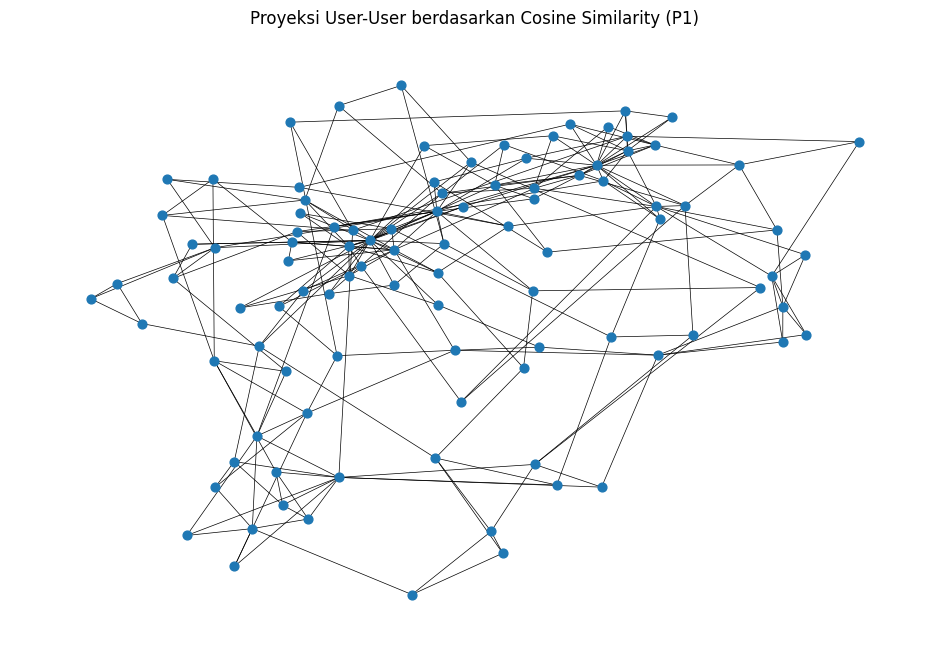

In [19]:
# Membuat proyeksi User–User dan visualisasi NetworkX

# Memilih 100 Visitor dengan interaksi terbanyak
user_activity = np.asarray(user_item_matrix.sum(axis=1)).ravel()
top_n = 100

top_users = np.argsort(user_activity)[-top_n:]
user_item_sample = user_item_matrix[top_users]

# Menghitung cosine similarity antar-User
similarity_matrix = cosine_similarity(user_item_sample)

# Membentuk graf User-User
G_user = nx.Graph()

for idx in range(len(top_users)):
    G_user.add_node(int(top_users[idx]))

# Menghubungkan setiap User dengan 3 User paling mirip
for i in range(len(top_users)):
    similarities = similarity_matrix[i].copy()
    similarities[i] = -1

    nearest = np.argsort(similarities)[-3:]

    for j in nearest:
        if similarities[j] > 0:
            G_user.add_edge(
                int(top_users[i]),
                int(top_users[j]),
                weight=float(similarities[j])
            )

print("Jumlah node:", G_user.number_of_nodes())
print("Jumlah edge:", G_user.number_of_edges())
print("Jumlah komponen:", nx.number_connected_components(G_user))
print("Rata-rata derajat:", round(
    sum(dict(G_user.degree()).values()) / G_user.number_of_nodes(), 2
))

# Visualisasi graf
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    node_size=40,
    with_labels=False,
    width=0.5
)

plt.title("Proyeksi User-User berdasarkan Cosine Similarity (P1)")
plt.axis("off")
plt.show()

Pada proyeksi User–User, digunakan 100 User dengan aktivitas tertinggi. Graf yang terbentuk memiliki 100 node, 246 edge, 1 komponen terhubung, dan rata-rata derajat 4,92. Visualisasi menunjukkan hubungan antar-User berdasarkan kemiripan pola interaksi mereka. User yang terhubung memiliki kemiripan nilai interaksi yang lebih besar dari nol, sedangkan semakin tinggi nilai cosine similarity, semakin mirip pola interaksi kedua User tersebut.

#### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Pada tahap ini, matriks User–Item ditransposisikan menjadi matriks Item–User. Baris mewakili Item dan kolom mewakili Visitor. Cosine similarity kemudian digunakan untuk membentuk proyeksi Item–Item berdasarkan kemiripan pola interaksi pengunjung.

In [20]:
# Membentuk matriks Item–User

# Membentuk matriks Item-User dari data P1
item_user_matrix = user_item_matrix.T.tocsr()

print("Dimensi matriks Item-User:", item_user_matrix.ndim)
print("Shape matriks:", item_user_matrix.shape)
print("Jumlah nilai nonzero:", item_user_matrix.nnz)

density = (
    item_user_matrix.nnz /
    (item_user_matrix.shape[0] * item_user_matrix.shape[1])
) * 100

print(f"Kepadatan matriks: {density:.6f}%")

Dimensi matriks Item-User: 2
Shape matriks: (181334, 765439)
Jumlah nilai nonzero: 1168246
Kepadatan matriks: 0.000842%


Jumlah node: 100
Jumlah edge: 234
Jumlah komponen: 4
Rata-rata derajat: 4.68


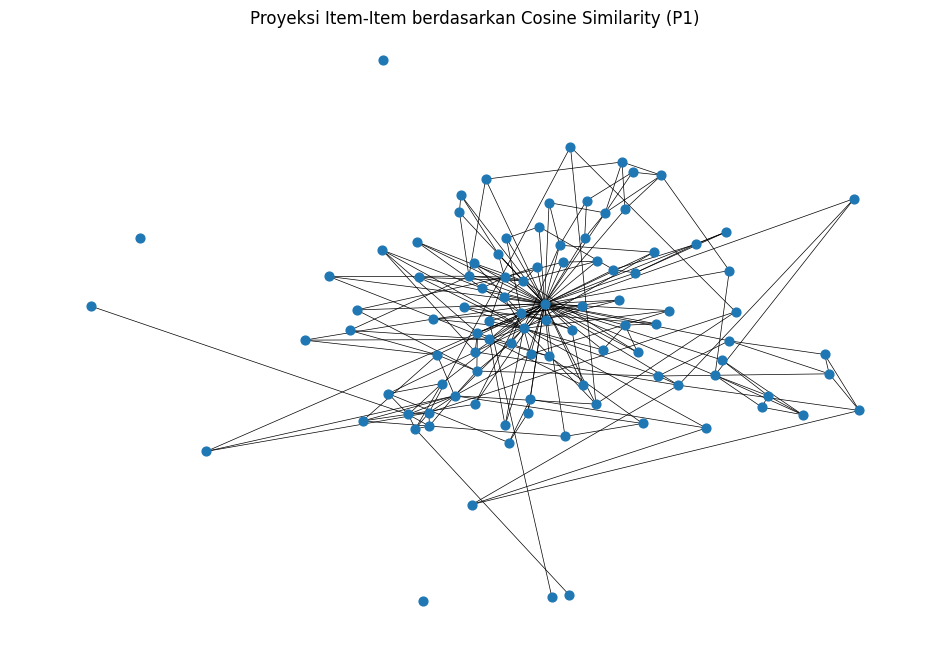

In [21]:
# Proyeksi Item–Item dan visualisasi NetworkX

# Memilih 100 Item dengan interaksi terbanyak
item_activity = np.asarray(item_user_matrix.sum(axis=1)).ravel()
top_n = 100

top_items = np.argsort(item_activity)[-top_n:]
item_user_sample = item_user_matrix[top_items]

# Menghitung cosine similarity antar-Item
similarity_matrix_item = cosine_similarity(item_user_sample)

# Membentuk graf Item-Item
G_item = nx.Graph()

for idx in range(len(top_items)):
    G_item.add_node(int(top_items[idx]))

# Menghubungkan setiap Item dengan 3 Item paling mirip
for i in range(len(top_items)):
    similarities = similarity_matrix_item[i].copy()
    similarities[i] = -1

    nearest = np.argsort(similarities)[-3:]

    for j in nearest:
        if similarities[j] > 0:
            G_item.add_edge(
                int(top_items[i]),
                int(top_items[j]),
                weight=float(similarities[j])
            )

print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())
print("Jumlah komponen:", nx.number_connected_components(G_item))
print("Rata-rata derajat:", round(
    sum(dict(G_item.degree()).values()) / G_item.number_of_nodes(), 2
))

# Visualisasi graf Item-Item
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    node_size=40,
    with_labels=False,
    width=0.5
)

plt.title("Proyeksi Item-Item berdasarkan Cosine Similarity (P1)")
plt.axis("off")
plt.show()

Matriks Item–User diperoleh dengan melakukan transpose terhadap matriks User–Item. Dengan demikian, baris mewakili Item dan kolom mewakili User. Nilai matriks tetap merepresentasikan frekuensi interaksi, sehingga matriks ini digunakan untuk menghitung cosine similarity antar-Item.

VSM pada simpul Item dilakukan dengan membentuk matriks Item–User dari data interaksi periode P1 (training). Baris matriks mewakili produk (`Item`), sedangkan kolom mewakili pengunjung (`Visitor`).

Matriks yang dihasilkan memiliki dimensi 2 dengan *shape* (181.334, 765.439), yang berarti terdapat 181.334 Item dan 765.439 User. Jumlah nilai nonzero sebanyak 1.168.246, dengan kepadatan matriks sebesar 0,000842%. Kepadatan yang rendah menunjukkan bahwa hanya sebagian kecil pasangan Item–User yang memiliki interaksi.

Selanjutnya, dilakukan proyeksi Item–Item menggunakan cosine similarity pada 100 Item dengan interaksi terbanyak. Berdasarkan visualisasi NetworkX, graf memiliki 100 node, 234 edge, 4 komponen terhubung, dan rata-rata derajat 4,68. Graf menunjukkan hubungan kemiripan antarproduk berdasarkan pola interaksi pengunjung. Adanya 4 komponen terhubung berarti graf terbagi menjadi empat kelompok yang tidak semuanya saling terhubung melalui jalur yang sama.

#### 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Proyeksi User–User memiliki 246 edge, 1 komponen terhubung, dan rata-rata derajat 4,92. Sementara itu, proyeksi Item–Item memiliki 234 edge, 4 komponen terhubung, dan rata-rata derajat 4,68.

Dari hasil tersebut, proyeksi User–User lebih baik untuk eksplorasi ini karena memiliki lebih banyak edge dan seluruh node terhubung dalam satu komponen. Hal ini menunjukkan bahwa hubungan kemiripan antar-User pada graf sampel lebih merata dibandingkan proyeksi Item–Item yang terbagi menjadi empat komponen.

Dari segi efisiensi, kedua proyeksi menggunakan matriks sparse dengan kepadatan yang sama, yaitu 0,000842%. Oleh karena itu, berdasarkan hasil yang tersedia, belum dapat dipastikan bahwa salah satunya lebih hemat waktu atau memori. Namun, proyeksi User–User lebih baik dari segi keterhubungan graf pada sampel yang digunakan.

#### 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

**a.Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)**

Cosine similarity dihitung untuk User acuan yang dipilih dari sampel. User acuan tidak dimasukkan ke dalam hasil, sehingga diperoleh lima User lain dengan nilai similarity tertinggi.

**b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!**

Nilai similarity yang diperoleh dari Python disimpan sebagai properti `similarity` pada relationship `SIMILAR_TO`. Setelah itu, query Cypher digunakan untuk menampilkan kembali lima pasangan User dengan nilai similarity tertinggi.

a. Menghitung lima User dengan similarity tertinggi

In [22]:
# Hitung cosine similarity menggunakan Python

import numpy as np
import pandas as pd

# Memilih User acuan dari 100 User sampel
reference_idx = 0
reference_user = int(user_ids[top_users[reference_idx]])

# Mengambil nilai similarity terhadap User acuan
scores = similarity_matrix[reference_idx].copy()

# Tidak memasukkan User acuan sebagai hasil
scores[reference_idx] = -1

# Mengambil 5 User dengan similarity tertinggi
top_5_idx = np.argsort(scores)[-5:][::-1]

similarity_results = pd.DataFrame({
    "User_Acuan": reference_user,
    "User_Mirip": [
        int(user_ids[top_users[i]]) for i in top_5_idx
    ],
    "Similarity": [
        float(scores[i]) for i in top_5_idx
    ]
})

display(similarity_results)

,User_Acuan,User_Mirip,Similarity
0,625795,316850,0.141264
1,625795,673572,0.129184
2,625795,1035814,0.114883
3,625795,895999,0.104897
4,625795,389532,0.089519


b. Menyimpan nilai similarity ke Neo4j

In [23]:
from neo4j import GraphDatabase

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:

        for _, row in similarity_results.iterrows():
            session.run("""
                MATCH (u1:Visitor {visitorId: $user1})
                MATCH (u2:Visitor {visitorId: $user2})
                MERGE (u1)-[r:SIMILAR_TO]->(u2)
                SET r.similarity = $similarity
            """,
                user1=int(row["User_Acuan"]),
                user2=int(row["User_Mirip"]),
                similarity=float(row["Similarity"])
            )

print("Nilai similarity berhasil disimpan ke Neo4j.")

Nilai similarity berhasil disimpan ke Neo4j.


In [25]:
# Query Cypher untuk menampilkan 5 hasil tertinggi

reference_user = int(similarity_results.iloc[0]["User_Acuan"])

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run("""
            MATCH (u1:Visitor {visitorId: $reference_user})
                  -[r:SIMILAR_TO]->(u2:Visitor)
            RETURN
                u1.visitorId AS User_Acuan,
                u2.visitorId AS User_Mirip,
                r.similarity AS Similarity
            ORDER BY r.similarity DESC
            LIMIT 5
        """, reference_user=reference_user)

        similarity_check = pd.DataFrame([dict(record) for record in result])

display(similarity_check)

,User_Acuan,User_Mirip,Similarity
0,625795,316850,0.141264
1,625795,673572,0.129184
2,625795,1035814,0.114883
3,625795,895999,0.104897
4,625795,389532,0.089519


Berdasarkan perhitungan cosine similarity pada proyeksi User–User, diperoleh lima User dengan nilai similarity tertinggi terhadap User acuan 625795. Nilai similarity tertinggi sebesar 0,141264 diperoleh pada User 316850, sedangkan nilai terendah dari lima hasil tersebut sebesar 0,089519 pada User 389532.

Nilai similarity yang diperoleh dari Python kemudian disimpan ke Neo4j sebagai properti similarity pada relasi SIMILAR_TO. Hasil query menunjukkan bahwa nilai similarity berhasil ditampilkan kembali dari graf dan diurutkan dari nilai tertinggi. Nilai similarity dari Python dan Neo4j perlu dicocokkan untuk memastikan bahwa data tersimpan dengan benar.

#### 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

Pada bagian ini, graf interaksi RetailRocket ditampilkan sebelum perhitungan similarity, kemudian dibandingkan dengan graf User–User setelah relationship `SIMILAR_TO` ditambahkan. Visualisasi dibuat menggunakan NetworkX berdasarkan data yang diambil dari Neo4j.

Jumlah node: 79
Jumlah edge: 77


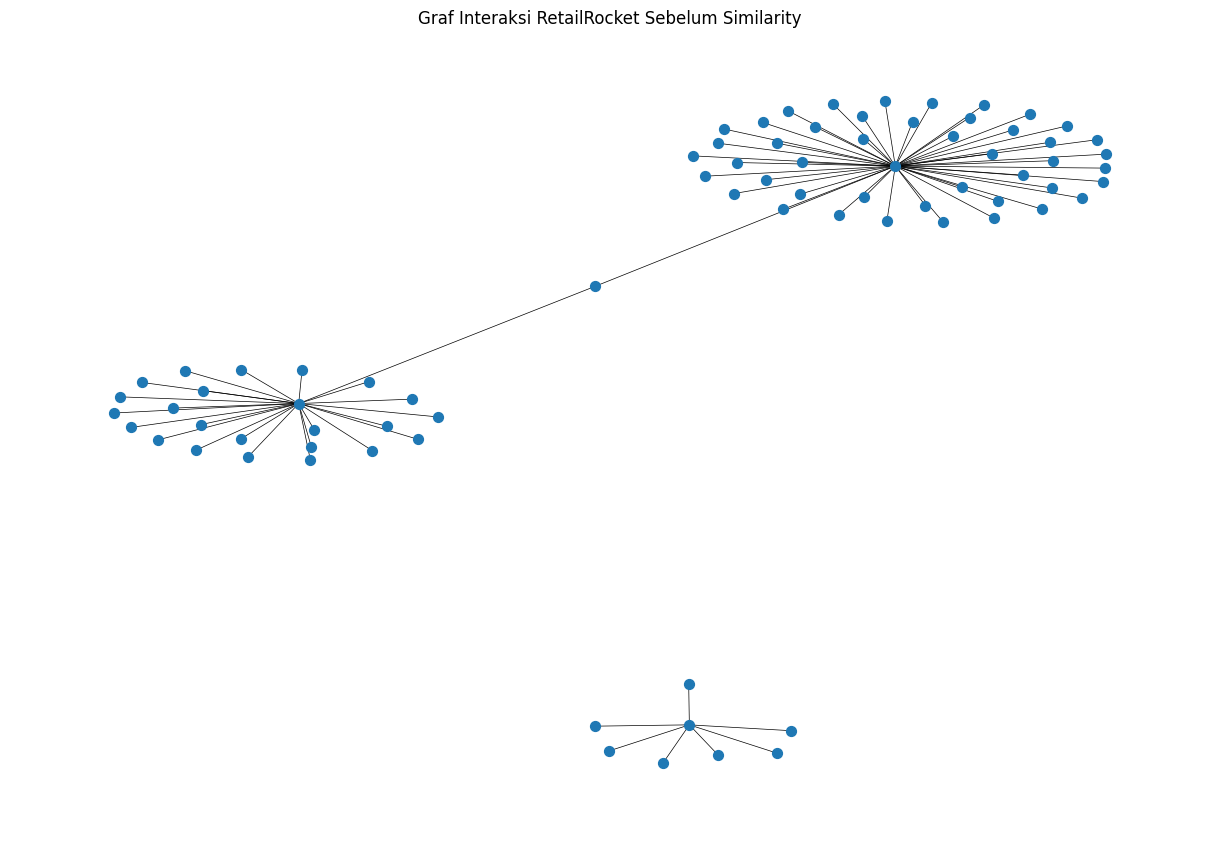

In [26]:
from neo4j import GraphDatabase
import networkx as nx
import matplotlib.pyplot as plt

# Mengambil contoh graf interaksi asli dari Neo4j
query_before = """
MATCH (u:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN u.visitorId AS visitor,
       type(r) AS relasi,
       i.itemId AS item
LIMIT 100
"""

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query_before)
        records_before = [dict(record) for record in result]

# Membuat graf NetworkX
G_before = nx.Graph()

for row in records_before:
    G_before.add_edge(
        f"V{row['visitor']}",
        f"I{row['item']}",
        relasi=row["relasi"]
    )

print("Jumlah node:", G_before.number_of_nodes())
print("Jumlah edge:", G_before.number_of_edges())

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_before, seed=42)
nx.draw(
    G_before, pos,
    node_size=50,
    with_labels=False,
    width=0.5
)
plt.title("Graf Interaksi RetailRocket Sebelum Similarity")
plt.axis("off")
plt.show()

Jumlah node: 6
Jumlah edge: 5


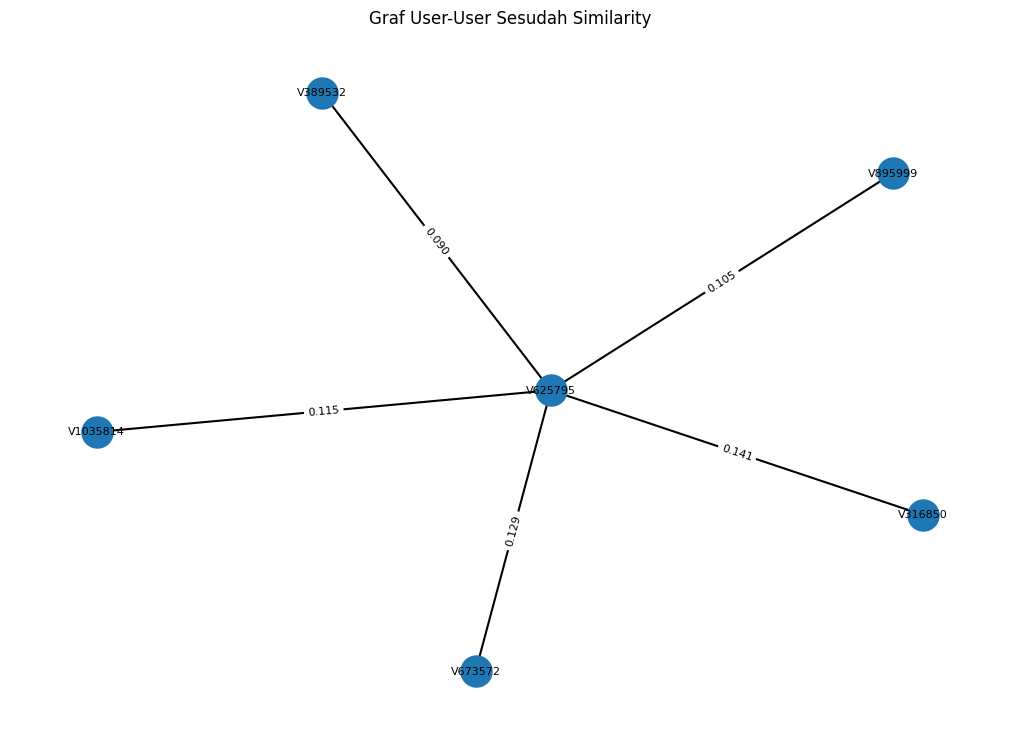

In [27]:
query_after = """
MATCH (u1:Visitor)-[r:SIMILAR_TO]->(u2:Visitor)
RETURN u1.visitorId AS user1,
       u2.visitorId AS user2,
       r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query_after)
        records_after = [dict(record) for record in result]

# Membuat graf similarity
G_after = nx.Graph()

for row in records_after:
    G_after.add_edge(
        f"V{row['user1']}",
        f"V{row['user2']}",
        weight=row["similarity"]
    )

print("Jumlah node:", G_after.number_of_nodes())
print("Jumlah edge:", G_after.number_of_edges())

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G_after, seed=42)

nx.draw(
    G_after, pos,
    node_size=500,
    with_labels=True,
    font_size=8,
    width=1.5
)

edge_labels = {
    (u, v): f"{data['weight']:.3f}"
    for u, v, data in G_after.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_after, pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title("Graf User-User Sesudah Similarity")
plt.axis("off")
plt.show()

Sebelum similarity, graf yang ditampilkan memiliki 79 node dan 77 edge. Graf tersebut menggambarkan hubungan antara Visitor dan Item melalui relationship interaksi, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Visualisasi dibatasi hingga 100 baris hasil query sehingga hanya menunjukkan sebagian data.

Graf sesudah similarity menampilkan lima relationship SIMILAR_TO dengan nilai similarity tertinggi. Graf tersebut terdiri dari enam node dan lima edge, dengan satu User acuan yang terhubung ke lima User lain. 

Kedua grafik memiliki tujuan berbeda. Grafik pertama menunjukkan interaksi Visitor–Item, sedangkan grafik kedua menunjukkan kemiripan antar-User. Oleh karena itu, keduanya digunakan untuk memperlihatkan perbedaan jenis hubungan, bukan sebagai perbandingan langsung seluruh isi graf.

## 2.2 Analytics

#### 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

Pada tahap ini, dibuat sistem rekomendasi menggunakan metode K-Nearest Neighbors (KNN). Data P1 digunakan untuk membentuk matriks interaksi User–Item dan mencari lima User yang memiliki pola interaksi paling mirip dengan User target. Rekomendasi dibuat berdasarkan Item yang pernah diakses oleh User tetangga, dengan mengecualikan Item yang sudah pernah diakses oleh User target.

##### a. Membentuk Matriks User–Item

Data P1 digunakan sebagai data training. Pasangan User–Item yang sama dihapus agar setiap pasangan hanya dihitung satu kali. Selanjutnya, data diubah menjadi matriks sparse yang digunakan untuk menghitung kemiripan antar-User.

In [65]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# Membaca data
p1 = pd.read_csv("data/events_P1.csv")
p2 = pd.read_csv("data/events_P2.csv")

# Mengambil pasangan user-item unik dari P1
train_interactions = p1[["visitorid", "itemid"]].drop_duplicates()

user_ids = train_interactions["visitorid"].unique()
item_ids = train_interactions["itemid"].unique()

user_index = {u: i for i, u in enumerate(user_ids)}
item_index = {item: i for i, item in enumerate(item_ids)}

rows = train_interactions["visitorid"].map(user_index).to_numpy()
cols = train_interactions["itemid"].map(item_index).to_numpy()

user_item_train = csr_matrix(
    (np.ones(len(rows)), (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

print("Shape matriks training:", user_item_train.shape)
print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))

Shape matriks training: (765439, 181334)
Jumlah user: 765439
Jumlah item: 181334


##### b. Membentuk Model KNN dan Menghasilkan Rekomendasi

Model KNN menggunakan cosine distance untuk mencari User yang paling mirip dengan User target. Nilai similarity diperoleh dari \(1-\text{distance}\). Item yang sering muncul pada interaksi User tetangga mendapat skor lebih tinggi, sedangkan Item yang sudah pernah diakses oleh User target tidak dimasukkan kembali ke daftar rekomendasi.

In [66]:
knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)

knn.fit(user_item_train)

def get_recommendations(target_user, k=5):
    target_idx = user_index[target_user]

    distances, indices = knn.kneighbors(
        user_item_train[target_idx],
        n_neighbors=k + 1
    )

    # Mengambil lima tetangga selain target user
    neighbors = []
    for idx, dist in zip(indices[0], distances[0]):
        if idx != target_idx:
            neighbors.append((idx, dist))

        if len(neighbors) == k:
            break

    neighbor_indices = [idx for idx, _ in neighbors]

    seen_items = set(
        p1.loc[p1["visitorid"] == target_user, "itemid"].unique()
    )

    scores = np.asarray(
        user_item_train[neighbor_indices].sum(axis=0)
    ).ravel()

    # Menghilangkan item yang sudah pernah diakses
    for item in seen_items:
        if item in item_index:
            scores[item_index[item]] = 0

    recommendations = []
    for idx in np.argsort(-scores, kind="stable"):
        if scores[idx] > 0:
            recommendations.append({
                "itemid": int(item_ids[idx]),
                "skor": int(scores[idx])
            })

        if len(recommendations) == 5:
            break

    neighbor_info = [
        {
            "visitorid": int(user_ids[idx]),
            "similarity": round(float(1 - dist), 4)
        }
        for idx, dist in neighbors
    ]

    return recommendations, neighbor_info

##### c. Pemilihan User secara Acak

Pemilihan User dilakukan menggunakan random seed `42` agar prosesnya dapat diulang dengan hasil yang sama. Kandidat dipilih dari User yang muncul pada data P2 dan memiliki minimal lima Item unik pada data training. Dari kandidat tersebut, dipilih User pertama yang menghasilkan lima rekomendasi agar hasilnya dapat digunakan untuk evaluasi Hit@5 dan NDCG@5.

In [67]:
seed = 42
rng = np.random.default_rng(seed)

users_test = set(p2["visitorid"].unique())

eligible_users = np.array([
    user for user in user_ids
    if user in users_test
    and user_item_train[user_index[user]].nnz >= 5
])

shuffled_users = rng.permutation(eligible_users)

target_user = None
recommendations = []
neighbors = []

for user in shuffled_users:
    recs, neighbor_info = get_recommendations(int(user), k=5)

    if len(recs) >= 5:
        target_user = int(user)
        recommendations = recs
        neighbors = neighbor_info
        break

if target_user is None:
    raise ValueError(
        "Tidak ditemukan user yang menghasilkan lima rekomendasi "
        "dengan prosedur ini. Jangan menambahkan item secara manual."
    )

recommendation_df = pd.DataFrame(recommendations)

print("Seed random:", seed)
print("User terpilih:", target_user)
print("Jumlah kandidat awal:", len(eligible_users))

print("\nLima tetangga terdekat:")
display(pd.DataFrame(neighbors))

print("\nTop 3 rekomendasi (jawaban nomor 1b):")
display(recommendation_df.head(3))

print("\nLima rekomendasi untuk evaluasi:")
display(recommendation_df.head(5))

Seed random: 42
User terpilih: 1257226
Jumlah kandidat awal: 3528

Lima tetangga terdekat:


,visitorid,similarity
0,460734,0.3430
1,567547,0.3254
2,1048612,0.3234
3,26848,0.2572
4,1113813,0.2425



Top 3 rekomendasi (jawaban nomor 1b):


,itemid,skor
0,182413,2
1,252483,2
2,454300,1



Lima rekomendasi untuk evaluasi:


,itemid,skor
0,182413,2
1,252483,2
2,454300,1
3,400460,1
4,438986,1


Dengan random seed `42`, User yang terpilih adalah `1257226` dari 3.528 kandidat awal. Lima tetangga terdekat memiliki nilai similarity antara 0,2425 hingga 0,3430.

Berdasarkan interaksi kelima tetangga tersebut, diperoleh tiga rekomendasi teratas, yaitu Item `182413` dengan skor 2, Item `252483` dengan skor 2, dan Item `454300` dengan skor 1. Skor menunjukkan jumlah tetangga yang berinteraksi dengan Item tersebut. Karena dua Item teratas memiliki skor sama, urutan keduanya mengikuti urutan kandidat pada proses pemeringkatan.

#### 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah: (a) Hit@5        (b) NDCG@5

Evaluasi dilakukan dengan membandingkan lima Item hasil rekomendasi dengan interaksi User pada periode testing (P2). Metrik yang digunakan adalah Hit@5 untuk melihat apakah terdapat Item relevan dalam lima rekomendasi teratas, serta NDCG@5 untuk menilai posisi Item relevan dalam daftar rekomendasi.

In [68]:
relevant_items = set(
    p2.loc[p2["visitorid"] == target_user, "itemid"].unique()
)

top5_items = recommendation_df["itemid"].head(5).tolist()

hits = [
    int(item in relevant_items)
    for item in top5_items
]

# Hit@5
hit_at_5 = float(sum(hits) > 0)

# DCG@5
dcg_at_5 = sum(
    hit / np.log2(rank + 2)
    for rank, hit in enumerate(hits)
)

# IDCG@5
ideal_hits = min(len(relevant_items), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 2)
    for rank in range(ideal_hits)
)

# NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

evaluation_df = pd.DataFrame({
    "Rank": range(1, len(top5_items) + 1),
    "Item ID": top5_items,
    "Relevan di P2": hits
})

print("Jumlah item relevan di P2:", len(relevant_items))
display(evaluation_df)

print("Hit@5:", round(hit_at_5, 4))
print("NDCG@5:", round(ndcg_at_5, 4))

Jumlah item relevan di P2: 1


,Rank,Item ID,Relevan di P2
0,1,182413,1
1,2,252483,0
2,3,454300,0
3,4,400460,0
4,5,438986,0


Hit@5: 1.0
NDCG@5: 1.0


Berdasarkan hasil evaluasi, terdapat satu Item relevan pada periode P2. Item `182413` berada pada peringkat pertama dan termasuk Item relevan, sedangkan empat Item lainnya tidak ditemukan dalam interaksi User pada periode testing.

Nilai Hit@5 sebesar **1,0** menunjukkan bahwa setidaknya satu dari lima rekomendasi sesuai dengan interaksi aktual User pada P2. Nilai NDCG@5 sebesar **1,0** menunjukkan bahwa Item relevan tersebut berada pada peringkat pertama. Hasil ini menunjukkan bahwa rekomendasi berhasil menemukan Item relevan untuk User yang diuji.